In [3]:
import pandas as pd
import numpy as np

# NLP
import re
import nltk
from nltk.corpus import stopwords

# ML
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Vijay\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [4]:
df = pd.read_csv("Fake.csv")   
df2 = pd.read_csv("True.csv")
# Add labels
df["label"] = 0   # Fake
df2["label"] = 1  # Real
# change if needed
# Combine both datasets
data = pd.concat([df, df2])
data = data.sample(frac=1).reset_index(drop=True)
print(data.head())

                                               title  \
0       Kuwait's Emir in hospital for medical checks   
1          Government announces new education policy   
2  Celebrity reveals unbelievable conspiracy behi...   
3  Secret government document proves impossible e...   
4      Hopes and frustrations as Brexit talks resume   

                                                text        subject  \
0  KUWAIT (Reuters) - Kuwait's elderly ruler was ...      worldnews   
1  The government announced a new education polic...       politics   
2  An online article makes dramatic claims about ...  entertainment   
3  The article cites a supposed secret document b...   politicsNews   
4  BRUSSELS (Reuters) - British and EU negotiator...      worldnews   

                 date  label  
0   November 22, 2017      1  
1        May 27, 2017      1  
2  September 12, 2017      0  
3       July 14, 2017      0  
4  September 24, 2017      1  


In [6]:
stop_words = set(stopwords.words('english'))
def clean_text(text):
    text = text.lower()  # lowercase
    text = re.sub(r'[^a-zA-Z]', ' ', text)  # remove special chars
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)
                                              
# Apply cleaning
data['text'] = data['text'].apply(clean_text)

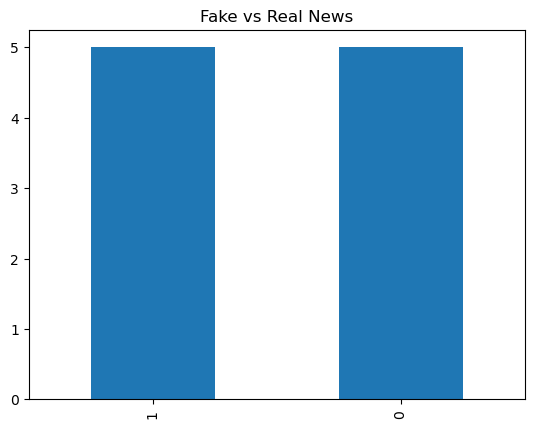

In [7]:
import matplotlib.pyplot as plt

# Count of fake vs real
data['label'].value_counts().plot(kind='bar')
plt.title("Fake vs Real News")
plt.show()

In [8]:
X = data['text']
y = data['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
vectorizer = TfidfVectorizer(max_features=5000)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [10]:
model = LogisticRegression()

model.fit(X_train_vec, y_train)

LogisticRegression()

In [11]:
y_pred = model.predict(X_test_vec)

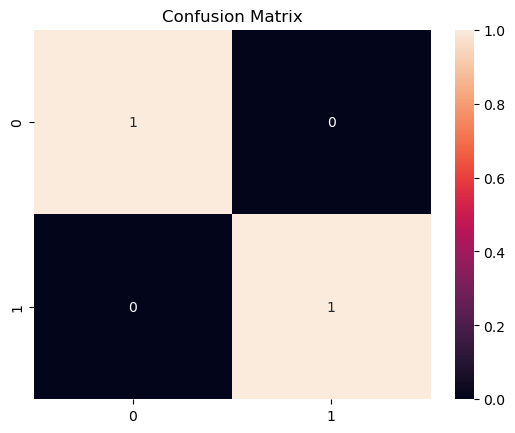

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

In [13]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



In [14]:
from sklearn.naive_bayes import MultinomialNB
 
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)
 
y_pred_nb = nb.predict(X_test_vec)
print("NB Accuracy:", accuracy_score(y_test, y_pred_nb))

NB Accuracy: 0.5


In [15]:
def predict_news(text):
    text = clean_text(text)
    vector = vectorizer.transform([text])
    result = model.predict(vector)
 
    if result[0] == 0:
        return "Fake News ❌"
    else:
        return "Real News ✅"
 
# Example
print(predict_news("Breaking: Government announces new policy"))

Real News ✅


In [16]:
print(predict_news("The government announced a new education policy aimed at improving access to education."))

Real News ✅


In [17]:
print(predict_news("The World Health Organization released a report highlighting improvements in global health."))

Fake News ❌


In [18]:
# Balance dataset
min_len = min(len(df), len(df2))

df = df.sample(min_len)
df2 = df2.sample(min_len)

data = pd.concat([df, df2])
data = data.sample(frac=1).reset_index(drop=True)

In [19]:
vectorizer = TfidfVectorizer(max_features=5000)

In [20]:
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2))

In [21]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train_vec, y_train)

MultinomialNB()

In [22]:
def predict_news(text):
    text = clean_text(text)
    vector = vectorizer.transform([text])
    
    prob = model.predict_proba(vector)
    result = model.predict(vector)
    
    print("Confidence:", prob)
    
    if result[0] == 0:
        return "Fake News ❌"
    else:
        return "Real News ✅"

In [23]:
# Recreate vectorizer and train again
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2))

X_train_vec = vectorizer.fit_transform(X_train)  # THIS is important
X_test_vec = vectorizer.transform(X_test)

# Train model again
from sklearn.naive_bayes import MultinomialNB
model = MultinomialNB()
model.fit(X_train_vec, y_train)

MultinomialNB()

In [24]:
print(predict_news("The government announced a new education policy aimed at improving access to education."))

Confidence: [[0.5 0.5]]
Fake News ❌


In [25]:
print(predict_news("The World Health Organization released a report highlighting improvements in global health."))

Confidence: [[0.55609861 0.44390139]]
Fake News ❌
